In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from som_rl.som.som_backend import SharpZSOMBackend, SharpZBackendConfig
from som_rl.env.schedules import SchedulerConfig, make_scheduler
from som_rl.env.env import SOMEnergyEnvConfig, EnvTeleportNodeRandomBin

from som_rl.eval.rollout import run_episode
from som_rl.eval.ideal_som import get_perfect_bins, plot_bins_triptych

import torch

print("torch:", torch.__version__)

torch: 2.10.0


In [2]:
# Monkey-patch backend.get_reward() so eval/rollout can use energy_E as trace

def _backend_get_reward(self):
    return float(self.energy_E())

SharpZSOMBackend.get_reward = _backend_get_reward

print("Patched SharpZSOMBackend.get_reward -> energy_E")

Patched SharpZSOMBackend.get_reward -> energy_E


In [3]:
# Load SOM / correlation data and perfect SOM bins
DATA = "data"  # adjust if needed

npz = np.load(f"{DATA}/correlations_dl/npairs_compact.npz")
dd, dr, rd, rr = npz["dd"], npz["dr"], npz["rd"], npz["rr"]

node_indices_photo = np.load(f"{DATA}/node_indices_fc.npy")  # (Nphot,)
initial_node_bins  = np.load(f"{DATA}/nodes_labels_initial_fc_200_ext.npy")  # (40000,)
reference_labels   = np.load(f"{DATA}/reference_labels_fc_fc.npy")  # (Nref,) in [0..10]

weighted_clusters  = np.load(f"{DATA}/weighted_clusters_5c_1t200.npy")  # (L,40000)
umatrix = np.load(f"{DATA}/umat.npy")  # (200,200)

perfect_bins = get_perfect_bins()
print("perfect_bins shape:", perfect_bins.shape)

b_cfg = SharpZBackendConfig(
    grid_shape=(200, 200),
    num_bins=11,
    objective_mode="energy",
    proposal_bin_mode="uniform_other",
)


def make_backend():
    return SharpZSOMBackend(
        cfg=b_cfg,
        dd=dd, dr=dr, rd=rd, rr=rr,
        node_indices_photo=node_indices_photo,
        initial_node_bins=initial_node_bins,
        reference_labels=reference_labels,
        umatrix=umatrix,
        weighted_clusters=weighted_clusters,
    )

backend_test = make_backend()
print("Initial energy_E():", backend_test.energy_E())

perfect_bins shape: (40000,)
Initial energy_E(): 0.023775093565945846


In [4]:
# SharpZ baseline policy: random node choice (can swap for smarter heuristic later)

def sharpz_random_policy(obs, rng: np.random.Generator):
    # EnvTeleportNodeRandomBin expects an integer node index in [0, H*W)
    H, W = env.H, env.W  # env passed via closure in run loop
    return rng.integers(0, H * W, dtype=np.int64)

In [24]:
# Helper to build a SharpZ env with level_list=range(30,201) and configurable loops

levels = tuple(range(30, 81))  # 30..200 inclusive
HITS_PER_LEVEL = 2


def make_sharpz_env(level_loops: int, max_steps: int = 100_000):
    sched_cfg = SchedulerConfig(
        max_steps=max_steps,              # global cap from scheduler side
        level_min=min(levels),
        level_max=max(levels),
        level_list=levels,
        min_accepts_per_level=HITS_PER_LEVEL,
        repeat_levels=True,
        level_loops=level_loops,
        # Temperature coupled to level
        T_max=1.0,
        T_min=0.01,
        temp_mode="exp",
        temp_evolve_with="level",
        # Floor coupled to level, decreasing (lower floor at higher level)
        min_abs_deltaE=5e-5,          # floor at highest level
        max_abs_deltaE=1e-4,          # floor at lowest level
        floor_evolve_with="level",
        floor_mode="exp",
        floor_direction="decreasing",
        floor_power=0.8,
    )

    env_cfg = SOMEnergyEnvConfig(
        grid_shape=(200, 200),
        obs_mode="global",
        max_steps=0,                  # ignored because use_env_max_steps=False
        use_env_max_steps=False,
        reset_backend_on_reset=False,
        initial_level=min(levels),
        initial_temperature=1.0,
        reward_type="deltaE",
        use_tanh_reward=True,
        reward_tanh_temperature=1e-2,
        reward_energy_scale=1.0,
        clip_reward=1.0,
        reject_penalty=0.0001,
        noop_penalty=0.00001,
    )

    backend = make_backend()
    sched = make_scheduler("level_hits", sched_cfg)
    env = EnvTeleportNodeRandomBin(backend, env_cfg, scheduler=sched)
    return env

In [25]:
# Run a few full SharpZ episodes with different level_loops and collect stats

snapshot_levels = [30, 80, 150, 200]  # levels at which to inspect bins (approx)

results = []

for loops in [1, 2, 3]:
    env = make_sharpz_env(level_loops=loops, max_steps=500_000)
    obs, info = env.reset()
    rng = np.random.default_rng(seed=loops)

    # Inline policy so it sees this env instance
    def policy(o, r):
        H, W = env.H, env.W
        return r.integers(0, H * W, dtype=np.int64)

    art = run_episode(env, policy, max_steps=200_000, seed=loops)
    print(f"loops={loops}: steps={len(art.log_df)}, trace_start={art.trace_start:.6f}, trace_end={art.trace_end:.6f}")

    # Per-level stats
    df = art.log_df.copy()
    df["hit"] = df["accepted"] & (~df["is_noop"])

    level_stats = []
    for lvl, g in df.groupby("level", dropna=True):
        steps_total = len(g)
        hits = int(g["hit"].sum())
        first_hit_idx = g.index[g["hit"]].min() if hits > 0 else None
        if first_hit_idx is not None:
            level_start_idx = g.index.min()
            steps_to_first_hit = int(first_hit_idx - level_start_idx + 1)
        else:
            steps_to_first_hit = None
        level_stats.append({
            "level": int(lvl),
            "steps_total": steps_total,
            "hits": hits,
            "steps_to_first_hit": steps_to_first_hit,
        })
    level_stats_df = pd.DataFrame(level_stats).sort_values("level")
    print(level_stats_df.head())

    results.append({"loops": loops, "art": art, "level_stats": level_stats_df})

loops=1: steps=200000, trace_start=0.023775, trace_end=0.030141
   level  steps_total  hits  steps_to_first_hit
0     30          247     2               147.0
1     31          284     2                82.0
2     32          285     2                34.0
3     33           39     2                15.0
4     34          253     2               133.0
loops=2: steps=200000, trace_start=0.023775, trace_end=0.030204
   level  steps_total  hits  steps_to_first_hit
0     30          303     2                 239
1     31          264     2                   7
2     32           92     2                  75
3     33           51     2                   8
4     34          200     2                  92
loops=3: steps=200000, trace_start=0.023775, trace_end=0.030192
   level  steps_total  hits  steps_to_first_hit
0     30          244     2                  13
1     31          299     2                 206
2     32           74     2                  60
3     33          104     2             

In [26]:
df = art.log_df
print(df[["t", "level", "T", "floor"]].head())

# Per-level averages:
print(df.groupby("level")[["T", "floor"]].mean())

   t  level    T   floor
0  1     30  1.0  0.0001
1  2     30  1.0  0.0001
2  3     30  1.0  0.0001
3  4     30  1.0  0.0001
4  5     30  1.0  0.0001
              T     floor
level                    
30     1.000000  0.000100
31     0.912011  0.000097
32     0.831764  0.000095
33     0.758578  0.000093
34     0.691831  0.000091
35     0.630957  0.000090
36     0.575440  0.000088
37     0.524807  0.000087
38     0.478630  0.000085
39     0.436516  0.000084
40     0.398107  0.000083
41     0.363078  0.000081
42     0.331131  0.000080
43     0.301995  0.000079
44     0.275423  0.000078
45     0.251189  0.000077
46     0.229087  0.000076
47     0.208930  0.000075
48     0.190546  0.000074
49     0.173780  0.000073
50     0.158489  0.000072


Using loops=1 for snapshots


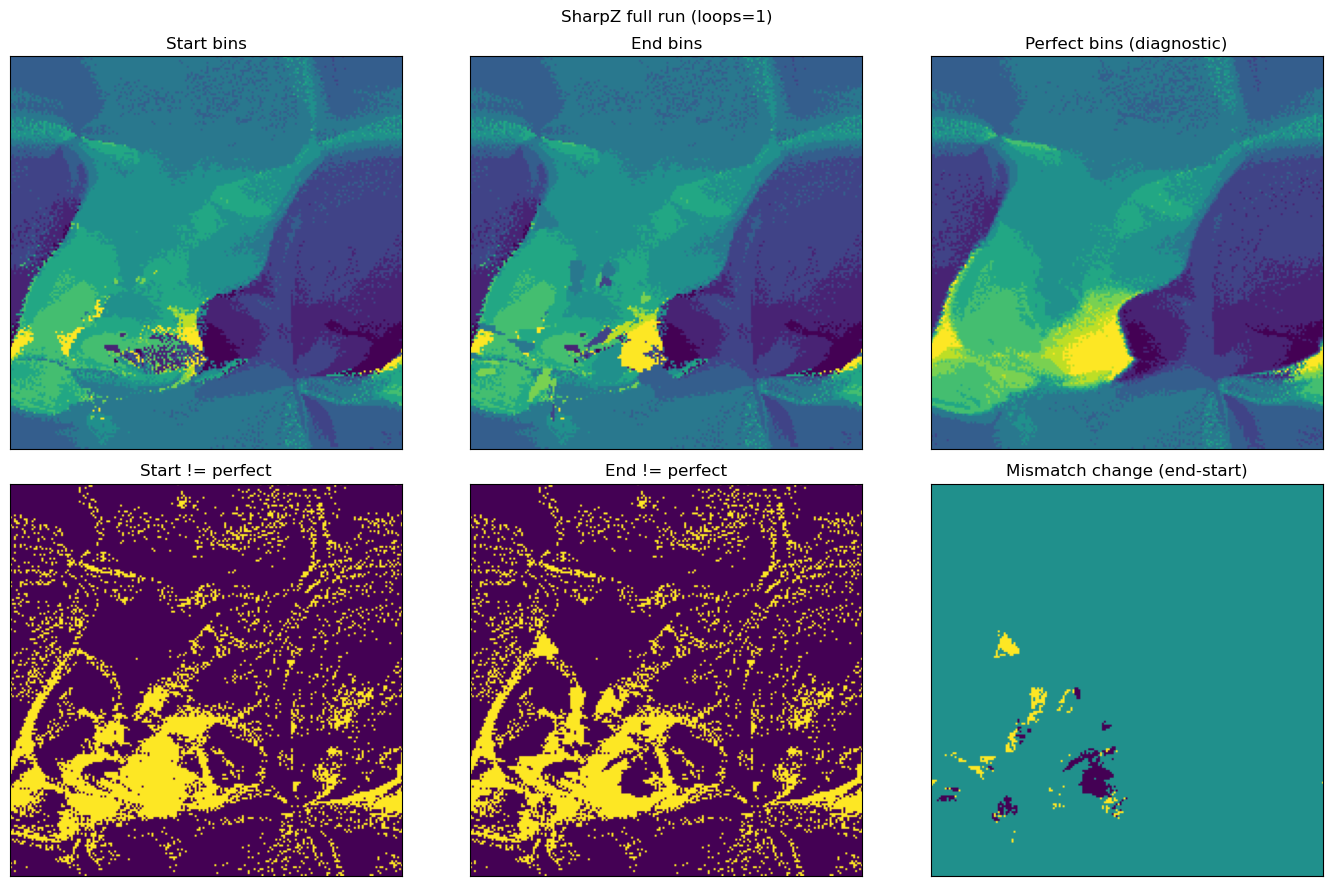

Match to perfect: start=0.795, end=0.797, Δ=+0.002


In [27]:
# Visualise a few snapshots vs perfect SOM for the last run

if results:
    last = results[0]
    art = last["art"]

    print(f"Using loops={last['loops']} for snapshots")
    start_bins = art.bins_start
    end_bins = art.bins_end

    # Simple triptych for overall start/end vs perfect
    plot_bins_triptych(start_bins, end_bins, perfect_bins, title=f"SharpZ full run (loops={last['loops']})")


In [28]:
df = results[2]["level_stats"]
df 
    

,level,steps_total,hits,steps_to_first_hit
0,30,244,2,13
1,31,299,2,206
2,32,74,2,60
3,33,104,2,61
4,34,133,2,28
5,35,120,2,118
6,36,652,2,192
7,37,1385,2,938
8,38,191,2,159
9,39,1028,2,950
